# Machine Learning: Exercise session 05

In this exercise session we explore LDA and QDA.

First, we generate and analyse synthetic datasets with different characteristics.
Visualizing the fitted models illustrates the differences between LDA and QDA.

Then, we analyse the [MNIST dataset](https://en.wikipedia.org/wiki/MNIST_database) using LDA and QDA models.

Lastly, we show for the one-dimensional case that in the the QDA classifier is a quadratic function of the predictor values.

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.axes import Axes

## Problem 1 - Synthetic Data

Modified example from https://scikit-learn.org/stable/modules/lda_qda.html


### Data generation

Since LDA and QDA are generative models,
we can generate synthetic data that perfectly fits the assumptions of LDA and QDA.
Complete the function below to generate a two-class dataset, split into training and test sets of indicated sizes, that fits the assumptions of LDA and QDA.

In [49]:
def make_two_class_dataset(
    n_train=100,
    n_test=1000,
    p_0=0.5,
    mean_0=(0, 0),
    mean_1=(1, 0),
    cov_0=np.eye(2),
    cov_1=np.eye(2),
    seed=42,
):
    # Set the seed for reproducibility
    np.random.seed(seed)

    # Total number of samples
    n_samples = 10000

    # Generate y
    y = np.random.binomial(1, p_0, size=n_samples)

    # Create an empty feature matrix (zeros as placeholders)
    X = np.zeros((n_samples, 2))

    # Sample the features based on class labels
    X[y == 0] = np.random.multivariate_normal(mean_0, cov_0, size=np.sum(y == 0))
    X[y == 1] = np.random.multivariate_normal(mean_1, cov_1, size=np.sum(y == 1))

    # Split the data into training and test sets
    X_train = X[:n_train]
    X_test = X[n_train:n_train + n_test]
    y_train = y[:n_train]
    y_test = y[n_train:n_train + n_test]

    return X_train, X_test, y_train, y_test

To see what the generated data looks like, complete the `plot_data` function below and call it with a dataset generated by your `make_two_class_dataset` function.
We use the object-based interface of `matplotlib` here, which makes it easier to combine multiple plots into one figure.
See the [documentation](https://matplotlib.org/stable/users/explain/figure/api_interfaces.html#api-interfaces) for details.

In [50]:
def plot_data(X, y, ax: Axes):
    # Plot a scatter plot of the data points
    # Class 0 in red, class 1 in blue
    ax.scatter(X[y == 0, 0], X[y == 0, 1], color='red', label='Class 0')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Class 1')

    # Set equal aspect ratio (makes circles look like circles etc.)
    ax.set_box_aspect(1)

    # Add a legend
    ax.legend()

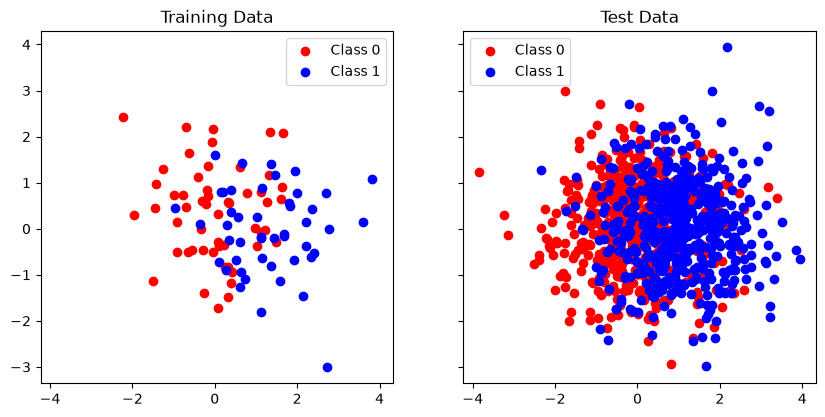

In [51]:
# Test the data generation and plotting
# Not specifying any arguments uses the default parameters
X_train, X_test, y_train, y_test = make_two_class_dataset()

# We split the plot into two subplots, one for training and one for test data
# Each subplot can be addressed via the axs array
fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
plot_data(X_train, y_train, axs[0])
axs[0].set_title("Training Data")
plot_data(X_test, y_test, axs[1])
axs[1].set_title("Test Data")
plt.show()

### Model fitting and evaluation

Fit an LDA and a QDA model to the training data and evaluate their accuracy on the test data.
Since we want to repeat this check for multiple different datasets, complete and call the `print_scores` function below.

In [82]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

# Specify `store_covariance=True` in the constructor to be able to analyze the estimated covariance matrices later
lda = LinearDiscriminantAnalysis(store_covariance=True)

qda = QuadraticDiscriminantAnalysis(store_covariance=True)

In [53]:
def print_scores(estimator, X_test, y_test):
    if isinstance(estimator, LinearDiscriminantAnalysis):
        model_name = "LDA"
    elif isinstance(estimator, QuadraticDiscriminantAnalysis):
        model_name = "QDA"
    else:
        model_name = "???"
    X_0 = X_test[y_test == 0]
    X_1 = X_test[y_test == 1]
    y_0 = y_test[y_test == 0]
    y_1 = y_test[y_test == 1]
    print(f"Test scores of {model_name}:")
    print(f"  on class 0: {estimator.score(X_0, y_0)}")
    print(f"  on class 1: {estimator.score(X_1, y_1)}")
    print(f"  overall:    {estimator.score(X_test, y_test)}")
    print()

In [54]:
lda.fit(X_train, y_train)
qda.fit(X_train, y_train)
print_scores(lda, X_test, y_test)
print_scores(qda, X_test, y_test)

Test scores of LDA:
  on class 0: 0.7645875251509054
  on class 1: 0.5984095427435387
  overall:    0.681

Test scores of QDA:
  on class 0: 0.778672032193159
  on class 1: 0.5765407554671969
  overall:    0.677



### Model visualization

In order to visualize the fitted models, complete the `plot_results` function below.
The functions `plot_ellipse` and `plot_decision_boundary` do what their names suggest and can be used as given below.

In [55]:
from matplotlib.patches import Ellipse
def plot_ellipse(mean, cov, color, ax: Axes):
    # Represents a mean+covariance as an ellipse
    v, w = np.linalg.eigh(cov)
    u = w[0] / np.linalg.norm(w[0])
    angle = np.arctan(u[1] / u[0])
    angle = 180 * angle / np.pi  # convert to degrees
    ell = Ellipse(
        mean,
        2 * v[0] ** 0.5,
        2 * v[1] ** 0.5,
        angle=180 + angle,
        facecolor=color,
    )
    ell.set_clip_box(ax.bbox)
    ell.set_alpha(0.4)
    ax.add_artist(ell)

In [56]:
from sklearn.inspection import DecisionBoundaryDisplay
def plot_decision_boundary(estimator, X, ax: Axes):
    DecisionBoundaryDisplay.from_estimator(
        estimator,
        X,
        response_method="predict_proba",
        plot_method="pcolormesh",
        ax=ax,
        cmap="RdBu",
        alpha=0.3,
    )
    DecisionBoundaryDisplay.from_estimator(
        estimator,
        X,
        response_method="predict_proba",
        plot_method="contour",
        ax=ax,
        alpha=1.0,
        levels=[0.5],
    )

In [57]:
def plot_results(estimator, X, y, ax: Axes):
    class_colors = ["red", "blue"]
    plot_decision_boundary(estimator, X, ax)
    y_pred = estimator.predict(X)
    for i in range(2):
        # Compute the indices of class i samples that are predicted (in)correctly
        ind_wrong = (y == i) & (y_pred != i)
        ind_right = (y == i) & (y_pred == i)

        # Make a scatter plot of the points
        # Use marker '.' for correctly classified points
        ax.scatter(X[ind_right, 0], X[ind_right, 1], c=class_colors[i], marker='.')
        # Use marker 'x' for incorrectly classified points
        ax.scatter(X[ind_wrong, 0], X[ind_wrong, 1], c=class_colors[i], marker='x')

    # Add ellipses for the estimated class means and covariances
    if isinstance(estimator, LinearDiscriminantAnalysis):
        covariances = [estimator.covariance_] * 2  # same covariance for both classes
    else:
        covariances = estimator.covariance_
    means = np.array(estimator.means_)
    plot_ellipse(means[0], covariances[0], class_colors[0], ax)
    plot_ellipse(means[1], covariances[1], class_colors[1], ax)

    # Plot the estimated class means as black points
    ax.scatter(means[:, 0], means[:, 1], c='black', marker='o', s=100)

    ax.set_box_aspect(1)

Test your function by calling it with the training data you generated above.

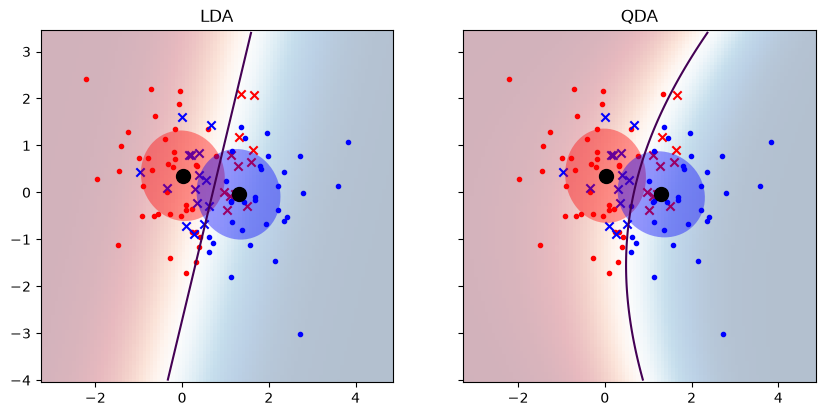

In [58]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
plot_results(lda, X_train, y_train, axs[0])
axs[0].set_title("LDA")
plot_results(qda, X_train, y_train, axs[1])
axs[1].set_title("QDA")
plt.show()

### Combined analysis

Lastly, we put the model fitting, plotting, and score computation together in an `analyze_dataset` function that takes care of everything.

In [59]:
def analyze_dataset(X_train, X_test, y_train, y_test ):
    # Fit estimators on training data
    lda = LinearDiscriminantAnalysis(store_covariance=True)
    lda.fit(X_train, y_train)

    qda = QuadraticDiscriminantAnalysis(store_covariance=True)
    qda.fit(X_train, y_train)

    # Plot Training data, LDA results, and QDA results
    _, axs = plt.subplots(1, 3, figsize=(10, 4), sharex=True, sharey=True)
    plot_data(X_train, y_train, axs[0])
    axs[0].set_title("Training Data")

    plot_results(lda, X_train, y_train, axs[1])
    axs[1].set_title("LDA Results")

    plot_results(qda, X_train, y_train, axs[2])
    axs[2].set_title("QDA Results")

    plt.show()

    # Compute and print scores on test data
    print_scores(lda, X_test, y_test)
    print_scores(qda, X_test, y_test)


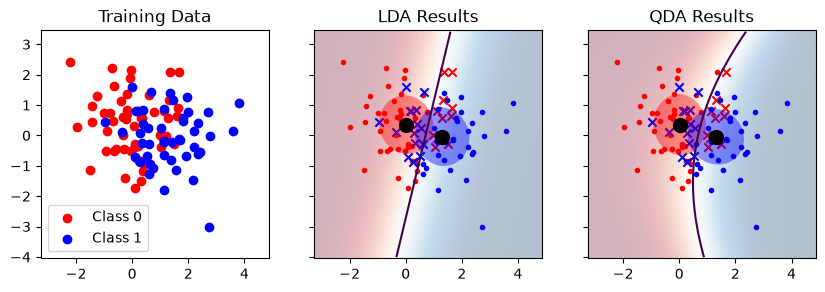

Test scores of LDA:
  on class 0: 0.7645875251509054
  on class 1: 0.5984095427435387
  overall:    0.681

Test scores of QDA:
  on class 0: 0.778672032193159
  on class 1: 0.5765407554671969
  overall:    0.677



In [60]:
# Create dataset and analyze it
X_train, X_test, y_train, y_test = make_two_class_dataset()
analyze_dataset(X_train, X_test, y_train, y_test)

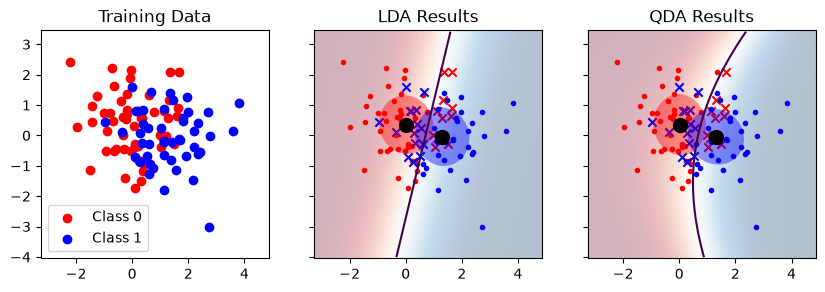

Test scores of LDA:
  on class 0: 0.7645875251509054
  on class 1: 0.5984095427435387
  overall:    0.681

Test scores of QDA:
  on class 0: 0.778672032193159
  on class 1: 0.5765407554671969
  overall:    0.677



In [61]:
# Shorter form using argument unpacking
# Warning: not very readable, only use when you are sure about arguments/returns!
data = make_two_class_dataset()
analyze_dataset(*data)

# or even:
# analyze_dataset(*make_two_class_dataset())

Using this "pipeline", we can now now generate and visualize LDA/QDA fits for different datasets.

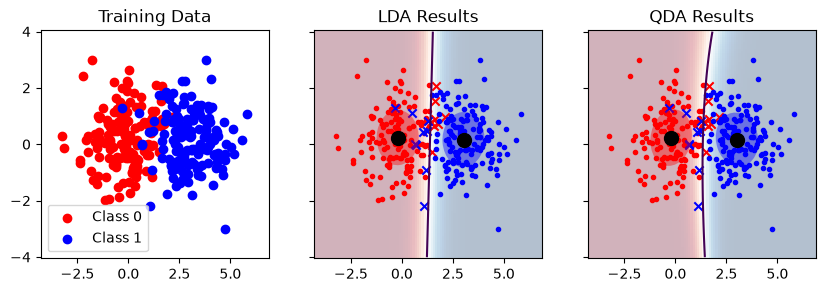

Test scores of LDA:
  on class 0: 0.900398406374502
  on class 1: 0.9538152610441767
  overall:    0.927

Test scores of QDA:
  on class 0: 0.9023904382470119
  on class 1: 0.9518072289156626
  overall:    0.927



In [62]:
# Example: same covariance, easy to separate, plenty of data
X_train, X_test, y_train, y_test = make_two_class_dataset(
    n_train=300,
    mean_1=(3, 0),
)
analyze_dataset(X_train, X_test, y_train, y_test)

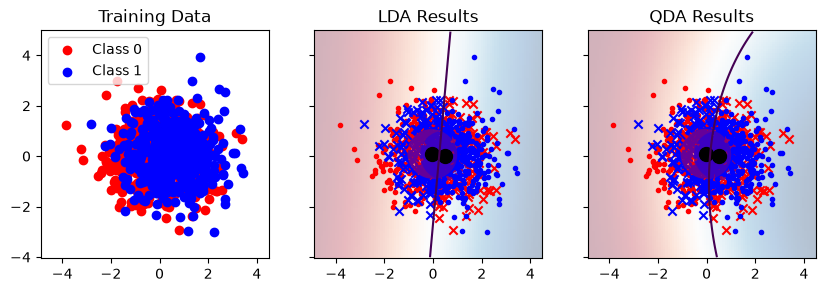

Test scores of LDA:
  on class 0: 0.5971074380165289
  on class 1: 0.6085271317829457
  overall:    0.603

Test scores of QDA:
  on class 0: 0.5702479338842975
  on class 1: 0.624031007751938
  overall:    0.598



In [63]:
# Example: same covariance, hard to separate, plenty of data
X_train, X_test, y_train, y_test = make_two_class_dataset(
    n_train=1000,
    mean_1=(0.5, 0),
)
analyze_dataset(X_train, X_test, y_train, y_test)

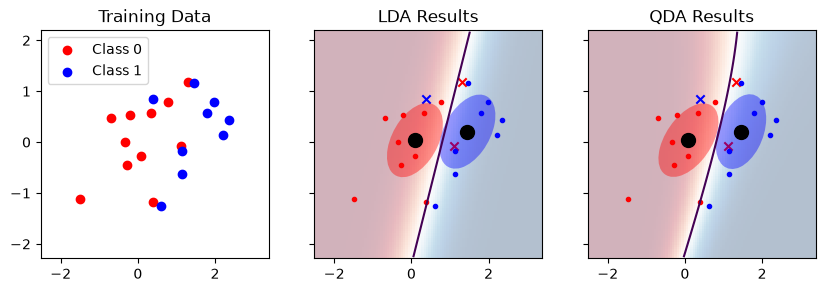

Test scores of LDA:
  on class 0: 0.7895791583166333
  on class 1: 0.5608782435129741
  overall:    0.675

Test scores of QDA:
  on class 0: 0.7875751503006012
  on class 1: 0.5668662674650699
  overall:    0.677



In [64]:
# Example: hard to separate, little data
X_train, X_test, y_train, y_test = make_two_class_dataset(
    n_train=20,
    mean_1=(1, 0),
)
analyze_dataset(X_train, X_test, y_train, y_test)

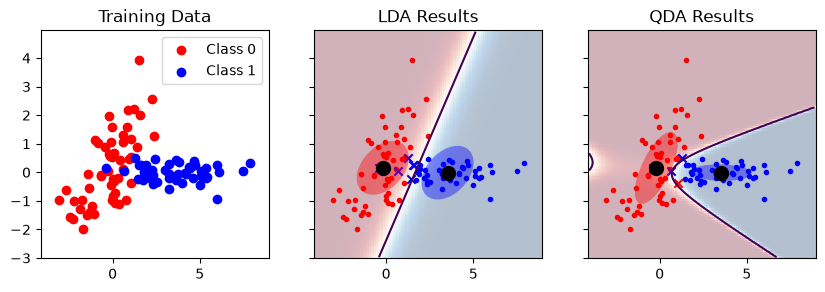

Test scores of LDA:
  on class 0: 0.9738430583501007
  on class 1: 0.7753479125248509
  overall:    0.874

Test scores of QDA:
  on class 0: 0.9476861167002012
  on class 1: 0.8767395626242545
  overall:    0.912



In [65]:
# Example: different covariances, easy to separate
cov_0 = np.array([[1.75, 1.25], [1.25, 1.75]])
cov_1 = np.array([[3, 0], [0, 0.1]])
X_train, X_test, y_train, y_test = make_two_class_dataset(
    n_train=100,
    mean_1=(3, 0),
    cov_0=cov_0,
    cov_1=cov_1,
)
analyze_dataset(X_train, X_test, y_train, y_test)

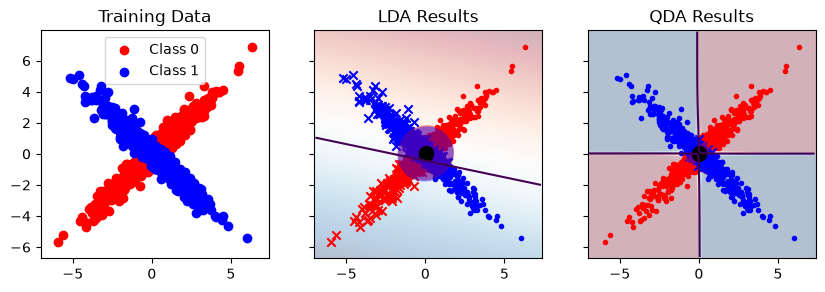

Test scores of LDA:
  on class 0: 0.5826446280991735
  on class 1: 0.374031007751938
  overall:    0.475

Test scores of QDA:
  on class 0: 0.9132231404958677
  on class 1: 0.939922480620155
  overall:    0.927



In [66]:
# Tricky example: different covariances, same mean
cov_0 = np.array([[3, 2.9], [2.9, 3]])
cov_1 = np.array([[3, -2.9], [-2.9, 3]])
X_train, X_test, y_train, y_test = make_two_class_dataset(
    n_train=1000,
    mean_1=(0, 0),
    cov_0=cov_0,
    cov_1=cov_1,
)
analyze_dataset(X_train, X_test, y_train, y_test)

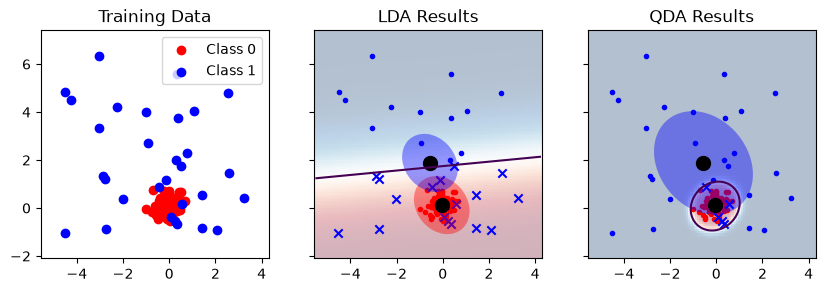

Test scores of LDA:
  on class 0: 1.0
  on class 1: 0.5170068027210885
  overall:    0.858

Test scores of QDA:
  on class 0: 0.9915014164305949
  on class 1: 0.9319727891156463
  overall:    0.974



In [67]:
# Example: small cluster vs. large cluster
cov_0 = np.array([[0.1, 0], [0, 0.1]])
cov_1 = np.array([[5, 0], [0, 5]])
X_train, X_test, y_train, y_test = make_two_class_dataset(
    n_train=100,
    p_0=0.3,
    mean_1=(0, 2),
    cov_0=cov_0,
    cov_1=cov_1,
)
analyze_dataset(X_train, X_test, y_train, y_test)

## Problem 2 - MNIST Data

### Setup and exploration

In [68]:
# Import package/module for data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [69]:
# Import modules for feature engineering and modelling
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)

from sklearn.metrics import accuracy_score

Import the dataset `digits.csv`, separate the predictors and the target variable and split it into training and test set. When you perform the splitting, set `random_state=40` and `test_size=50`.

In [70]:
dat = pd.read_csv("digits.csv")
random_state = 40
test_size =50

# Define X and Y
X = dat.iloc[:, 1:]
y = dat.iloc[:, 0]

In [71]:
# Split dataset into train-test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)

In [72]:
# Convert to numpy arrays (easier to plot etc.)
X_train = np.array(X_train)
y_train = np.array(y_train).ravel()
X_test = np.array(X_test)
y_test = np.array(y_test).ravel()

We now want to plot some of the observations of the dataset. Each row of the predictor matrix is 256 vector corresponding to a 16 x 16 image.

In [73]:
# Print the image as a 16x16 array
np.random.seed(42)
row_index = np.random.randint(0, len(X_train))
np.set_printoptions(linewidth = 150)
print(X_train[row_index].reshape(16, 16))

[[-1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.    -0.933  0.288  0.803 -0.999 -1.    -1.    -1.    -1.   ]
 [-1.    -1.    -1.    -1.    -1.    -1.    -1.    -0.954  0.457  0.959 -0.527 -1.    -1.    -1.    -1.    -1.   ]
 [-1.    -1.    -1.    -1.    -1.    -1.    -0.973  0.237  0.986 -0.315 -1.    -1.    -1.    -1.    -1.    -1.   ]
 [-1.    -1.    -1.    -1.    -1.    -0.99   0.143  1.     0.265 -1.    -1.    -1.    -1.    -1.    -1.    -1.   ]
 [-1.    -1.    -1.    -1.    -1.     0.042  1.     0.493 -0.964 -1.    -1.    -1.    -1.    -1.    -1.    -1.   ]
 [-1.    -1.    -1.    -1.     0.067  0.994  0.455 -0.945 -1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.   ]
 [-1.    -1.    -1.    -0.164  0.986  0.658 -0.908 -1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.   ]
 [-1.    -1.    -0.561  0.949  0.778 -0.724 -1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.   ]
 [-1.    -0.978  0.571  0.991 -0.456 -1.    -1.    -1.    -1.    -1.    -1.    -

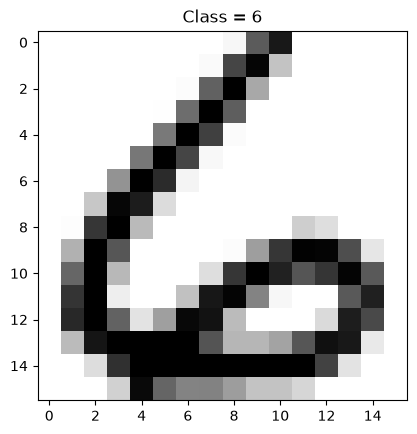

In [74]:
# Better: plot the array as an image
np.random.seed(42)
row_index = np.random.randint(0, len(X_train))
image_data = X_train[row_index].reshape(16, 16)
plt.imshow(image_data, cmap="binary")
plt.title(f"Class = {y_train[row_index]}")
plt.show()

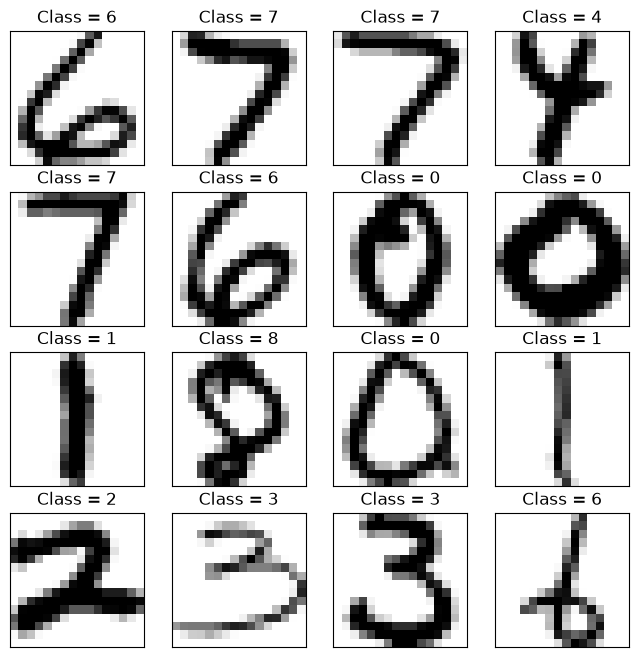

In [75]:
# Plot some figures
n_rows = 4
n_cols = 4
fig, ax = plt.subplots(n_rows, n_cols, figsize=(8, 8))
np.random.seed(42)
for i in range(n_rows):
    for j in range(n_cols):
        row_index = np.random.randint(0, len(X_train))
        image_data = X_train[row_index].reshape(16, 16)
        ax[i, j].imshow(image_data, cmap="binary")
        ax[i, j].set_title(f"Class = {y_train[row_index]}")
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
plt.show()

### LDA

We now try to fit an LDA model.
Mathematically, LDA is invariant under linear transformations (rescaling) of the predictors.
However, for numerical stability or when using regularization, it is a good idea to rescale the data anyways.
Create a `Pipeline` that first standardizes the data and then fits an LDA model.

In [76]:
# Define pipeline
lda = LinearDiscriminantAnalysis(shrinkage = 'auto', solver = 'lsqr')
scaler_lda = StandardScaler()
pipe_lda = Pipeline([
    ('scaler', scaler_lda),
    ('lda', lda)
])

# Fit pipeline
pipe_lda.fit(X_train, y_train)

# Predict on training data
y_pred_train = pipe_lda.predict(X_train)
print("LDA --- Accuracy on training data:", accuracy_score(y_train, y_pred_train))

# Predict on test data
y_pred_test = pipe_lda.predict(X_test)
print("LDA --- Accuracy on test data:", accuracy_score(y_test, y_pred_test))


LDA --- Accuracy on training data: 0.9324678911752521
LDA --- Accuracy on test data: 0.92


Since LDA estimates the class-conditional means, it can be useful to try to understand qualitatively how these look like. What do these mean correspond to?

In [77]:
# take a look at the conditional means
for class_label in np.unique(y_train):
    class_data = X_train[y_train == class_label]
    conditional_mean = class_data.mean(axis=0)
    print(f"Class {class_label} conditional mean:")
    print(conditional_mean)
    print()
    

Class 0 conditional mean:
[-0.99862005 -0.99537068 -0.98483404 -0.94092249 -0.83259225 -0.56971104 -0.12877928  0.15507919  0.0466428  -0.35443976 -0.74078602 -0.92044987
 -0.98493682 -0.99716596 -0.99993429 -1.         -0.99822409 -0.99349452 -0.95040185 -0.81159393 -0.48866807  0.06401264  0.52959478  0.68434457
  0.63262342  0.39985425 -0.05078602 -0.57908425 -0.87177506 -0.96892923 -0.99678096 -0.99999495 -0.99680792 -0.97431592 -0.86459309 -0.562631
 -0.05746925  0.43789217  0.62882308  0.61665122  0.55010025  0.52032687  0.38000253 -0.06550211 -0.56727464 -0.87723168 -0.9783631  -0.99810362
 -0.99421314 -0.93378349 -0.69239006 -0.21979528  0.2959604   0.5381011   0.44866217  0.21245493  0.09137742  0.21633446  0.39596799  0.26272283
 -0.17571609 -0.65133698 -0.92099158 -0.99401516 -0.97935468 -0.82602359 -0.42393345  0.09461415  0.46561331  0.45050969  0.14105223 -0.18770935
 -0.39066554 -0.23823083  0.11643976  0.31461668  0.12494271 -0.34052991 -0.76395535 -0.97005223 -0.948406

so each value is beetween -1 and 1 where -1 is the pixel is white and 1 is the pixel fully black. we can see most values for all numbers are negative (so closer to white but this will be easier to visualise with the plot that comes next)

Since we know that the data represents images of digits, we can try to plot the means as images.

In [78]:
def plot_means(means, method_name):
    plt.figure(figsize=(10, 5))
    for i in range(10):
        l1_plot = plt.subplot(2, 5, i + 1)
        l1_plot.imshow(means[i].reshape(16, 16), cmap="binary")
        l1_plot.set_xticks([])
        l1_plot.set_yticks([])
        l1_plot.set_xlabel(f"Class {i}")
    plt.suptitle("Means estimated by " + method_name)
    plt.show()

you can see that some images especially 2 and 4 are really distorted.

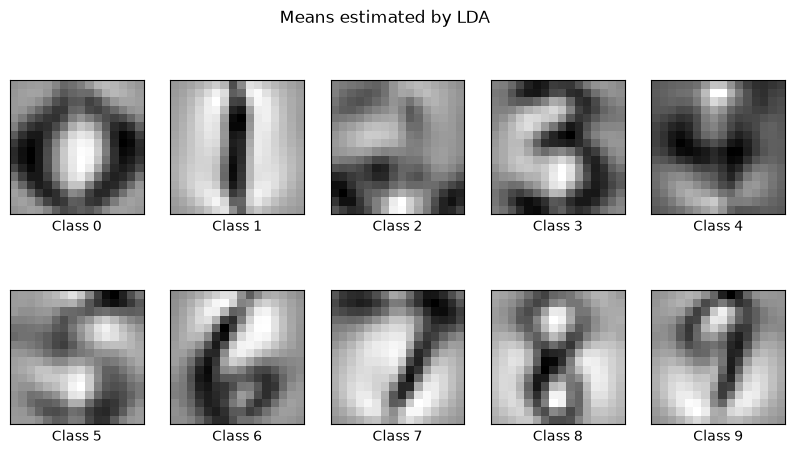

In [79]:
plot_means(lda.means_, "LDA")

Plotting the means, we see that they roughly look like the digits they are supposed to represent.
However, they are a bit distorted. Why is that and how could we fix that?

*Hint: Remember that we fitted an entire pipeline, not just the LDA estimator*

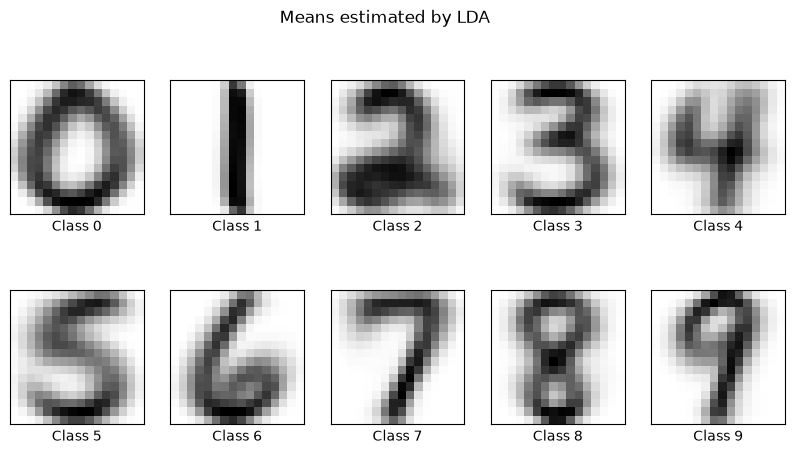

In [92]:
# Plot means estimated by LDA
lda_model = pipe_lda.named_steps["lda"]
scaler = pipe_lda.named_steps["scaler"]

# Means are in standardized space -> map them back to pixel space
lda_means = scaler.inverse_transform(lda_model.means_)

plot_means(lda_means, "LDA")

### QDA

Repeat the same analysis as above but now using QDA.
If you create a `QuadraticDiscriminantAnalysis` object without any arguments, you will see that it does not work properly.
Why is that?
Fix the problem by setting the argument `reg_param` to a small value (e.g. 0.01).

In [86]:
# QDA
QDA = QuadraticDiscriminantAnalysis(reg_param=0.01, store_covariance=True)

# Define pipeline
pipe_qda = Pipeline([
    ('scaler', StandardScaler()),
    ('qda', QDA)
])

# Fit pipeline
pipe_qda.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('qda', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,256
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [87]:
# Predict on training data
pipe_qda.predict(X_train)
print("QDA --- Accuracy on training data:", accuracy_score(y_train, pipe_qda.predict(X_train)))

# Predict on test data
pipe_qda.predict(X_test)
print("QDA --- Accuracy on test data:", accuracy_score(y_test, pipe_qda.predict(X_test)))

QDA --- Accuracy on training data: 0.9877088799889518
QDA --- Accuracy on test data: 0.92


As we did for LDA, plot the means estimated by QDA. Call the function you created by passing as an argument the matrix with the estimated means.

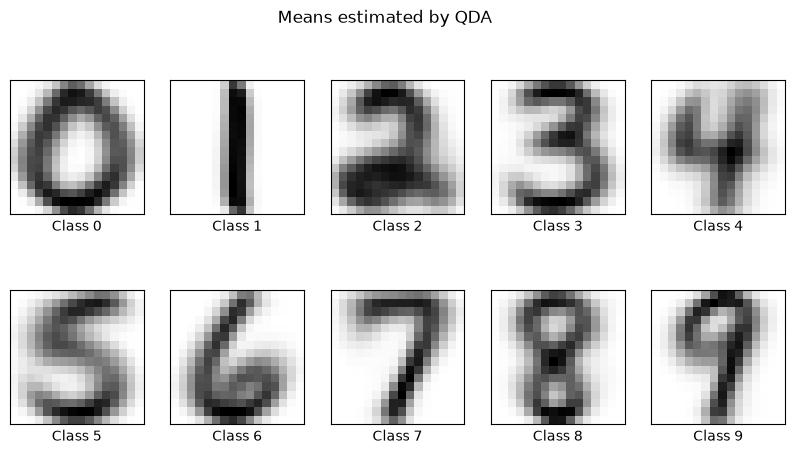

In [91]:
# Plot means estimated by QDA
qda_model = pipe_qda.named_steps["qda"]
scaler = pipe_qda.named_steps["scaler"]

# Means are in standardized space -> map them back to pixel space
qda_means = scaler.inverse_transform(qda_model.means_)

plot_means(qda_means, "QDA")

Do these look different from the means estimated by LDA? Why (not)?
Verify your answer using `numpy`.

In [93]:
close = np.allclose(lda_means, qda_means, rtol=1e-05, atol=1e-08)
print("Are LDA and QDA means close?", close)

Are LDA and QDA means close? True


_Bonus_: What do the estimated covariance matrices look like, what do they represent? Can you think of a way to visualize them?

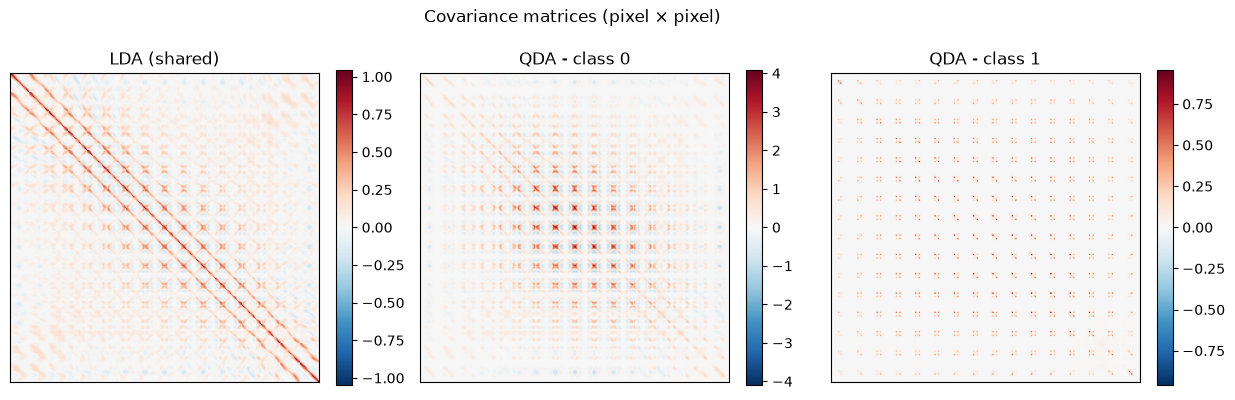

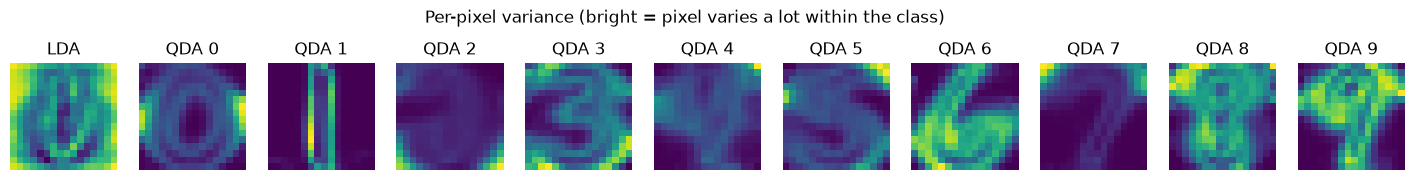

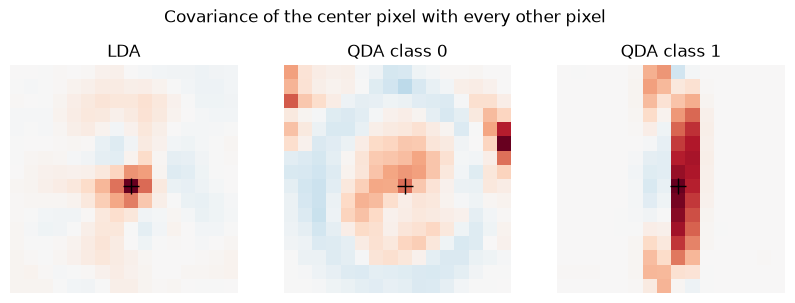

In [94]:
# claude answer

lda_model = pipe_lda.named_steps["lda"]
qda_model = pipe_qda.named_steps["qda"]

lda_cov = lda_model.covariance_               # (n_pixels, n_pixels): ONE matrix shared by all classes
qda_covs = np.array(qda_model.covariance_)    # (n_classes, n_pixels, n_pixels): one per class
n_pixels = lda_cov.shape[0]
side = int(np.sqrt(n_pixels))                 # image side length (e.g. 16 for 256 pixels)

def show_matrix(ax, M, title):
    vmax = np.abs(M).max()
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax)  # red = positive, blue = negative
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046)

# --- View 1: the raw covariance matrices (pixel x pixel) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
show_matrix(axes[0], lda_cov, "LDA (shared)")
show_matrix(axes[1], qda_covs[0], "QDA - class 0")
show_matrix(axes[2], qda_covs[1], "QDA - class 1")
fig.suptitle("Covariance matrices (pixel × pixel)")
plt.show()

# --- View 2: the diagonal = variance of each pixel, reshaped as an image ---
fig, axes = plt.subplots(1, 11, figsize=(18, 2.2))
axes[0].imshow(np.diag(lda_cov).reshape(side, side), cmap="viridis")
axes[0].set_title("LDA")
for k in range(qda_covs.shape[0]):
    axes[k + 1].imshow(np.diag(qda_covs[k]).reshape(side, side), cmap="viridis")
    axes[k + 1].set_title(f"QDA {k}")
for ax in axes:
    ax.axis("off")
fig.suptitle("Per-pixel variance (bright = pixel varies a lot within the class)")
plt.show()

# --- View 3: one row of the matrix = how one pixel co-varies with all the others ---
center = (side // 2) * side + side // 2       # index of the center pixel
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, M, title in [(axes[0], lda_cov, "LDA"),
                     (axes[1], qda_covs[0], "QDA class 0"),
                     (axes[2], qda_covs[1], "QDA class 1")]:
    row = M[center].reshape(side, side)
    vmax = np.abs(row).max()
    ax.imshow(row, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.plot(side // 2, side // 2, "k+", markersize=12)  # mark the reference pixel
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("Covariance of the center pixel with every other pixel")
plt.show()

## Problem 3

This problem is about quadratic discriminant analysis (QDA).
The observations within each class are modeled by a normal distribution with a class specific mean vector and a class specific covariance matrix. We consider the simple case where $p = 1$, (i.e., there is only one feature) and that we have $q = 2$ classes. Thus, for $j=0,1$, the conditional distribution $X\mid Y=j$ of the $j$-th class is one-dimensional normal $N(\mu_j, \sigma^2_j)$. 
Show that in this case, the QDA classifier is not linear in $x$, but _quadratic_,
i.e., that the decision boundary is given as the solution of a quadratic equation in $x$.

For $j = 0, 1$, $X \mid Y = j \sim N(\mu_j, \sigma_j^2)$, so

$$g_j(x) = \frac{1}{\sqrt{2\pi}\,\sigma_j} \exp\left\{-\frac{(x - \mu_j)^2}{2\sigma_j^2}\right\}$$

and let $\pi_j = \Pr(Y = j)$ be the prior probabilities.

Step 2: Write the QDA (Bayes) classification rule.

By Bayes’ formula, $\Pr(Y = j \mid X = x) \propto g_j(x)\,\pi_j$. The classifier picks the class with the largest posterior:

$$\hat y(x) = \arg\max_{j \in \{0,1\}} \; g_j(x)\,\pi_j$$

The decision boundary is the set of $x$ where both classes are equally likely:

$$\pi_0\, g_0(x) = \pi_1\, g_1(x)$$

Step 3: Take logs.

Since $\log$ is strictly increasing, the argmax and the boundary are unchanged. For each class:

$$\log\big(\pi_j g_j(x)\big) = -\frac{(x - \mu_j)^2}{2\sigma_j^2} - \log\sigma_j + \log\pi_j - \tfrac{1}{2}\log(2\pi)$$

The term $-\tfrac12\log(2\pi)$ is the same for both classes, so it can be dropped. This gives the discriminant function

$$\delta_j(x) = -\frac{(x - \mu_j)^2}{2\sigma_j^2} - \log\sigma_j + \log\pi_j$$

and the rule: predict class 1 if $\delta_1(x) > \delta_0(x)$, class 0 otherwise.

Step 4: Expand the square.

$$\delta_j(x) = -\frac{1}{2\sigma_j^2}\,x^2 + \frac{\mu_j}{\sigma_j^2}\,x - \frac{\mu_j^2}{2\sigma_j^2} - \log\sigma_j + \log\pi_j$$

Step 5: Set up the decision boundary $\delta_1(x) - \delta_0(x) = 0$ and collect terms.

$$\underbrace{\frac12\left(\frac{1}{\sigma_0^2} - \frac{1}{\sigma_1^2}\right)}_{a} x^2 + \underbrace{\left(\frac{\mu_1}{\sigma_1^2} - \frac{\mu_0}{\sigma_0^2}\right)}_{b} x + \underbrace{\frac{\mu_0^2}{2\sigma_0^2} - \frac{\mu_1^2}{2\sigma_1^2} + \log\frac{\sigma_0}{\sigma_1} + \log\frac{\pi_1}{\pi_0}}_{c} = 0$$

So the decision boundary is the solution set of

$$a x^2 + b x + c = 0$$

and the classifier predicts class 1 exactly when $a x^2 + bx + c > 0$.

Step 6: Conclude.

Because the variances are class-specific, in general $\sigma_0^2 \neq \sigma_1^2$, so $a \neq 0$. The $x^2$ term does not cancel, and the discriminant $\delta_1(x) - \delta_0(x)$ is a quadratic function of $x$. Hence the QDA classifier is quadratic in $x$, not linear. $\blacksquare$
